<a href="https://colab.research.google.com/github/Yukiii0517/BASC0017/blob/main/Dissertation_code_1V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The initial state is the pool has $x_0$ units of $X$ and $y_0$ units of $Y$: $x_0 y_0 = l_0^2$.

Typically, for intuitive understanding, we treat $X$ as the thing whose price is measured by $Y$, which is our numéraire (unit of account).

As an example, when $X$ is ETH and $Y$ is USDC, $P_0 = 2000$ means 1 ETH is worth 2000 USDC.

$q$ is measured in units of $X$, where $\theta_x = q$ means the trader takes out $Y$ and injects $X$, whereas $\theta_x = -q$ means the trader injects $Y$ and takes out $X$.

As an example, $\theta_x = q = 5$ means the trader injects 5 ETH and takes out the respective amount of USDC from the pool.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1) Define the Parameters (constants)
P0    = 2000.0          # pool price (typically how much USDC per ETH)
x0    = 50.0            # initial reserve of X(ETH) before our LP
q     = 5               # trade size
gamma = 0.997           # 1 - fee  (fee = 0.3%)

l0 = x0*np.sqrt(P0)     # initial liquidity


We optimise $\mathbb{E}[V(l)]$, the expected profit of a single LP providing
liquidity $l$, with respect to $l$. Writing $u = l + l_0$, the expected profit is
\begin{equation}
  \mathbb{E}[V(l)] = \frac{l}{l + l_0}\cdot\frac{G_a + G_b}{2},
\end{equation}
where $G_a$ and $G_b$ are the pool's gains from the trade (fee plus price impact)
in cases (a) and (b):
\begin{equation}
  G_a = P_0 q - \frac{\gamma P_0\, u\, q}{u + \gamma q\sqrt{P_0}},
  \qquad
  G_b = \frac{P_0\, u\, q}{\gamma\left(u - q\sqrt{P_0}\right)} - P_0 q .
\end{equation}

The FOC is
\begin{equation}
  l_0\,(G_a + G_b) + l\,(l + l_0)\left(\frac{\partial G_a}{\partial l}
  + \frac{\partial G_b}{\partial l}\right) = 0,
\end{equation}
where
\begin{equation}
  \frac{\partial G_a}{\partial l}
  = -\frac{\gamma^2 q^2 P_0^{3/2}}{\left(u + \gamma q\sqrt{P_0}\right)^2},
  \qquad
  \frac{\partial G_b}{\partial l}
  = -\frac{q^2 P_0^{3/2}}{\gamma\left(u - q\sqrt{P_0}\right)^2}.
\end{equation}

In [ ]:
# 2) Model Set Up
def Ga(l):
    u = l + l0
    return P0*q - gamma*P0*u*q/(u + gamma*q*np.sqrt(P0))

def Gb(l):
    u = l + l0
    return P0*u*q/(gamma*(u - q*np.sqrt(P0))) - P0*q

def dGa(l):
    u = l + l0
    return -gamma**2 * q**2 * P0**1.5 / (u + gamma*q*np.sqrt(P0))**2

def dGb(l):
    u = l + l0
    return -q**2 * P0**1.5 / (gamma*(u - q*np.sqrt(P0))**2)

def expected_profit(l):
    return l/(l + l0) * (Ga(l) + Gb(l))/2

def foc(l):
    return l0*(Ga(l) + Gb(l)) + l*(l + l0)*(dGa(l) + dGb(l))

In [ ]:
#3) use bisection to find l*
def bisection(f, lo, hi, tol=1e-10):
    while hi - lo > tol:
        mid = (lo + hi)/2
        if np.sign(f(mid)) == np.sign(f(lo)):
            lo = mid
        else:
            hi = mid
    return (lo + hi)/2

l_star = bisection(foc, 0, 5000)
print(f"l* = {l_star:.4f}")
print(f"E[V(l*)] = {expected_profit(l_star):.4f}")

l* = 2362.2071
E[V(l*)] = 265.5366


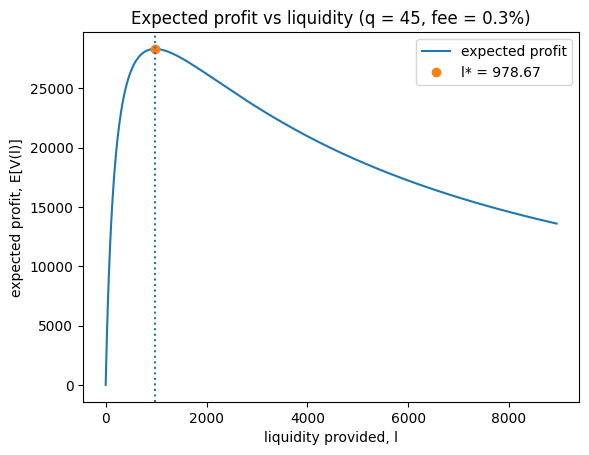

In [ ]:
# 4) Plot
l_grid = np.linspace(0, 4*l0, 800)
profit = expected_profit(l_grid)

plt.plot(l_grid, profit, label="expected profit")
plt.plot(l_star, expected_profit(l_star), "o", label=f"l* = {l_star:.2f}")
plt.axvline(l_star, linestyle=":")
plt.xlabel("liquidity provided, l")
plt.ylabel("expected profit, E[V(l)]")
plt.title(f"Expected profit vs liquidity (q = {q}, fee = {(1-gamma)*100:.1f}%)")
plt.legend()
plt.show()

From the last line of the written notes, the FOC can be simplified to the equation

$$
\left[l_0(1-\gamma) - k\left(1 - \gamma + \gamma^2\right)\right]u^2 + 2\gamma k\left[l_0 - (1-\gamma)k\right]u - \gamma^2k^3 = 0
$$

with $k = q\sqrt{P_0}$ and $u = l + l_0$. Using the quadratic formula to solve it,

$$
u = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a},
$$

where

$$
a = l_0(1-\gamma) - k\left(1 - \gamma + \gamma^2\right), \qquad
b = 2\gamma k\left[l_0 - (1-\gamma)k\right], \qquad
c = -\gamma^2k^3,
$$



Since the LP injects liquidity, we need $l > 0$, so we only take the root with $l > 0$.

In [ ]:
# Quadratic for l*
def l_star_quadratic(P0, x0, q, gamma, show=False):
    l0 = x0*np.sqrt(P0)

    # constraint to ensure at leasto one positive root
    if not ((1 - gamma)/(1 - gamma + gamma**2) < q/x0 < 1):
        return np.nan

    # 1) coefficients of a u^2 + b u + c = 0  (u = l + l0)
    a = l0*(1 - gamma) - q*np.sqrt(P0)*(1 - gamma + gamma**2)
    b = 2*gamma*q*np.sqrt(P0)*(l0 - (1 - gamma)*q*np.sqrt(P0))
    c = -gamma**2 * (q*np.sqrt(P0))**3

    # 2) discriminant
    Delta = b**2 - 4*a*c

    # 3) both roots from the quadratic formula
    u_plus  = (-b + np.sqrt(Delta))/(2*a) #since a < 0, u_plus should give the negative root
    u_minus = (-b - np.sqrt(Delta))/(2*a) #since a < 0, u_minus should give the positive root

    l_plus  = u_minus - l0
    l_minus = u_plus - l0

    # the LP injects liquidity, so we take the root with l > 0
    if l_plus > 0:
        l_quadratic = l_plus
    else:
        l_quadratic = l_minus

    if show:
        print(f"a = {a:.6f}")
        print(f"b = {b:.6f}")
        print(f"c = {c:.6f}")
        print(f"\nDelta    = {Delta:.6f}")
        print(f"\npositive root: l = {l_plus:.6f}")
        print(f"\nnegative root: l = {l_minus:.6f}")

    return l_quadratic

# 4) Compare bisection and quadratic solution (base case)
l_quadratic = l_star_quadratic(P0, x0, q, gamma, show=True)
print(f"\nl* from quadratic formula = {l_quadratic:.10f}")
print(f"l* from bisection         = {l_star:.10f}")
print(f"difference                = {abs(l_quadratic - l_star):.2e}")

a = -216.229786
b = 996700.900000
c = -11113358.471233

Delta    = 983800527570.000488

positive root: l = 2362.207150

negative root: l = -2224.890730

l* from quadratic formula = 2362.2071499611
l* from bisection         = 2362.2071499610
difference                = 3.46e-11


Now we want to investigate how the optimal liquidity $l^*$ changes with certain parameters, particularly $l_0$ (through $x_0$, since $l_0 = x_0\sqrt{P_0}$), $\gamma$, $P_0$ and $q$.

We vary one parameter at a time while fixing the others, and get the following graphs.


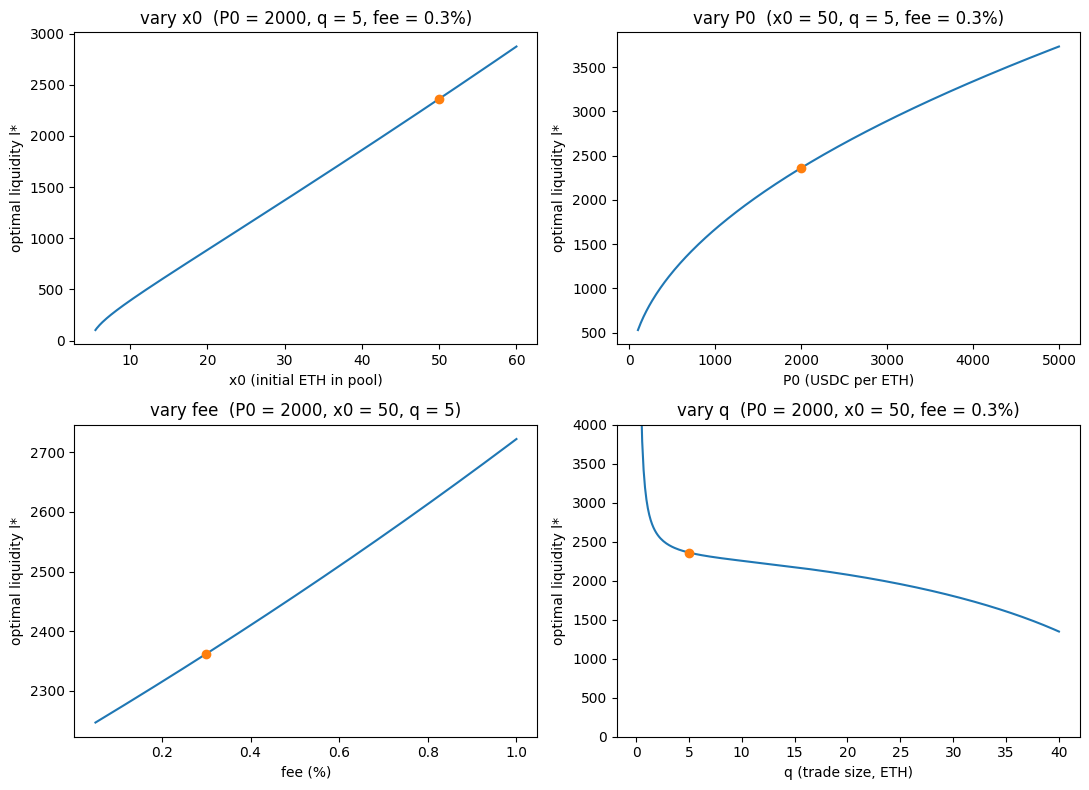

In [ ]:
x0_values  = np.linspace(5.5, 60, 300)
P0_values  = np.linspace(100, 5000, 300)
fee_values = np.linspace(0.0005, 0.01, 300)
q_values   = np.linspace(0.05, 40, 300)

l_vs_x0  = [l_star_quadratic(P0, v, q, gamma) for v in x0_values]
l_vs_P0  = [l_star_quadratic(v, x0, q, gamma) for v in P0_values]
l_vs_fee = [l_star_quadratic(P0, x0, q, 1 - f) for f in fee_values]
l_vs_q   = [l_star_quadratic(P0, x0, v, gamma) for v in q_values]

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

ax[0,0].plot(x0_values, l_vs_x0)
ax[0,0].plot(x0, l_quadratic, "o")
ax[0,0].set_xlabel("x0 (initial ETH in pool)")
ax[0,0].set_title(f"vary x0  (P0 = {P0:g}, q = {q}, fee = {(1-gamma)*100:.1f}%)")

ax[0,1].plot(P0_values, l_vs_P0)
ax[0,1].plot(P0, l_quadratic, "o")
ax[0,1].set_xlabel("P0 (USDC per ETH)")
ax[0,1].set_title(f"vary P0  (x0 = {x0:g}, q = {q}, fee = {(1-gamma)*100:.1f}%)")

ax[1,0].plot(fee_values*100, l_vs_fee)
ax[1,0].plot((1 - gamma)*100, l_quadratic, "o")
ax[1,0].set_xlabel("fee (%)")
ax[1,0].set_title(f"vary fee  (P0 = {P0:g}, x0 = {x0:g}, q = {q})")

ax[1,1].plot(q_values, l_vs_q)
ax[1,1].plot(q, l_quadratic, "o")
ax[1,1].set_xlabel("q (trade size, ETH)")
ax[1,1].set_ylim(0, 4000)
ax[1,1].set_title(f"vary q  (P0 = {P0:g}, x0 = {x0:g}, fee = {(1-gamma)*100:.1f}%)")

for ax_i in ax.flat:
    ax_i.set_ylabel("optimal liquidity l*")
plt.tight_layout()
plt.show()